# IMDB Sentiment Analysis using Deep Learning (RNN / LSTM)
Pipeline: Load data → Clean text → Tokenize & pad → Embedding + Bidirectional LSTM → Evaluate → Save → Predict

In [1]:
import re
import pickle
%pip install numpy
import numpy as np
%pip install pandas
import pandas as pd
%pip install matplotlib
import matplotlib.pyplot as plt
%pip install seaborn
import seaborn as sns

%pip install tensorflow
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
%pip install scikit-learn 
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

tf.random.set_seed(42)
np.random.seed(42)

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## 1. Load Data

In [2]:
df = pd.read_csv("IMDBDataset.csv")
df.info()
df['sentiment'].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


sentiment
positive    25000
negative    25000
Name: count, dtype: int64

## 2. Text Preprocessing
Same cleaning as before, with one important change for RNNs: negation words (*not, no, nor...*) are **kept**, because an RNN reads word order and needs *"not good"* to stay different from *"good"*.

In [ ]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
stop_words = set(ENGLISH_STOP_WORDS)

# keep negations - they flip sentiment
negations = {"no", "nor", "not", "don", "didn", "doesn", "isn", "wasn", "aren",
             "weren", "won", "wouldn", "couldn", "shouldn", "hadn", "hasn", "haven", "ain"}
stop_words = stop_words - negations

def clean_text(review):
    review = review.lower()
    review = re.sub(r'<.*?>', ' ', review)        # remove HTML tags
    review = re.sub(r"n't", " not", review)       # didn't -> did not
    review = re.sub(r'[^a-zA-Z]', ' ', review)    # remove special chars & numbers
    words = [w for w in review.split() if w not in stop_words]
    return ' '.join(words)

df['cleaned_review'] = df['review'].apply(clean_text)
df[['review', 'cleaned_review']].head()

NameError: name 'stopwords' is not defined

## 3. Labels and Train / Test Split
We split **before** fitting the tokenizer so the test set doesn't leak into the vocabulary.

In [ ]:
y = df['sentiment'].map({'positive': 1, 'negative': 0}).values

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['cleaned_review'], y,
    test_size=0.2, random_state=42, stratify=y
)
print(len(X_train_text), len(X_test_text))

40000 10000


## 4. Tokenization and Padding (replaces TF-IDF)
Each review becomes a **sequence of integer word IDs**, padded/truncated to a fixed length so the RNN can process batches.

In [ ]:
df['review_length'] = df['cleaned_review'].apply(lambda x: len(x.split()))
print(df['review_length'].describe())
print("95th percentile length:", int(df['review_length'].quantile(0.95)))

count    50000.000000
mean       121.564020
std         91.485482
min          3.000000
25%         65.000000
50%         90.500000
75%        148.000000
max       1436.000000
Name: review_length, dtype: float64
95th percentile length: 314


In [ ]:
VOCAB_SIZE = 20000     # keep the 20k most frequent words
MAX_LEN    = 200       # ~ covers most reviews (see percentile above)
OOV_TOKEN  = "<OOV>"

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV_TOKEN)
tokenizer.fit_on_texts(X_train_text)

X_train = pad_sequences(tokenizer.texts_to_sequences(X_train_text),
                        maxlen=MAX_LEN, padding='post', truncating='post')
X_test  = pad_sequences(tokenizer.texts_to_sequences(X_test_text),
                        maxlen=MAX_LEN, padding='post', truncating='post')

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("Example sequence:", X_train[0][:20])

X_train shape: (40000, 200)
X_test shape : (10000, 200)
Example sequence: [ 902   44 1351  334 1461   55 8482 1505   14   33   64  537  726  719
   27 1505 2668  244    9 1627]


## 5. Build the RNN Model
Embedding → Bidirectional LSTM → Dense layers → Sigmoid output.

In [ ]:
import itertools
from tensorflow.keras import backend as K
from tensorflow.keras.optimizers import Adam
EMBED_DIM = 128
# 1. Model builder that accepts hyperparameters
def build_final_model(lstm_units=64, dropout=0.5, lr=1e-3):
    model = Sequential([
        Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM),
        Bidirectional(LSTM(lstm_units, dropout=0.2, recurrent_dropout=0.0)),
        Dense(64, activation='relu'),
        Dropout(dropout),
        Dense(1, activation='sigmoid')
    ])
    model.compile(loss='binary_crossentropy',
                  optimizer=Adam(learning_rate=lr),
                  metrics=['accuracy'])
    return model


In [ ]:
print("VOCAB_SIZE:", VOCAB_SIZE, "| MAX_LEN:", MAX_LEN)
print("X_train max id:", X_train.max(), "| shape:", X_train.shape)

VOCAB_SIZE: 10000 | MAX_LEN: 100
X_train max id: 19999 | shape: (40000, 200)


## 6. Train

In [ ]:

param_grid = {
    'batch_size': [64, 128, 256],
    'lstm_units': [32, 64],
    'lr':         [1e-3, 5e-4],
}
MAX_EPOCHS = 30   # EarlyStopping decides when to actually stop

best_val_acc = 0.0
best_configuration = {}
results = []

keys = list(param_grid.keys())
for values in itertools.product(*param_grid.values()):
    params = dict(zip(keys, values))
    print(f"\n=== Running: {params} ===")

    K.clear_session()
    model = build_final_model(lstm_units=params['lstm_units'], lr=params['lr'])

    ckpt_name = "best_bs{batch_size}_u{lstm_units}_lr{lr}.keras".format(**params)
    callbacks = [
        EarlyStopping(monitor='val_accuracy', mode='max',
                      patience=3, restore_best_weights=True),
        ModelCheckpoint(ckpt_name, monitor='val_accuracy', mode='max',
                        save_best_only=True)
    ]

    history = model.fit(
        X_train, y_train,
        epochs=MAX_EPOCHS,
        batch_size=params['batch_size'],
        validation_split=0.1,
        callbacks=callbacks,
        verbose=1
    )

    val_accs = history.history['val_accuracy']
    best_idx = int(np.argmax(val_accs))
    run_acc  = val_accs[best_idx]
    run_loss = history.history['val_loss'][best_idx]

    print(f"Best epoch: {best_idx + 1} | val_accuracy: {run_acc:.4f} | val_loss: {run_loss:.4f}")

    results.append({**params, 'best_epoch': best_idx + 1,
                    'val_accuracy': run_acc, 'val_loss': run_loss,
                    'model_file': ckpt_name})

    if run_acc > best_val_acc:
        best_val_acc = run_acc
        best_configuration = results[-1]

# 3. Summary table, sorted by val_accuracy
results_df = pd.DataFrame(results).sort_values('val_accuracy', ascending=False)
print("\nHYPERPARAMETER SEARCH COMPLETE")
print(results_df.to_string(index=False))
print("\nBest configuration:", best_configuration)

# 4. Load the winner and evaluate once on the untouched test set
model = load_model(best_configuration['model_file'])
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy of best model: {test_acc * 100:.2f}%")


=== Running: {'batch_size': 64, 'lstm_units': 32, 'lr': 0.001} ===
Epoch 1/30


InvalidArgumentError: Graph execution error:

Detected at node sequential_1/embedding_1/GatherV2 defined at (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "/opt/anaconda3/envs/dl-mac/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>

  File "/opt/anaconda3/envs/dl-mac/lib/python3.11/site-packages/traitlets/config/application.py", line 1080, in launch_instance

  File "/opt/anaconda3/envs/dl-mac/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 768, in start

  File "/opt/anaconda3/envs/dl-mac/lib/python3.11/site-packages/tornado/platform/asyncio.py", line 211, in start

  File "/opt/anaconda3/envs/dl-mac/lib/python3.11/asyncio/base_events.py", line 608, in run_forever

  File "/opt/anaconda3/envs/dl-mac/lib/python3.11/asyncio/base_events.py", line 1936, in _run_once

  File "/opt/anaconda3/envs/dl-mac/lib/python3.11/asyncio/events.py", line 84, in _run

  File "/

## 7. Training Curves

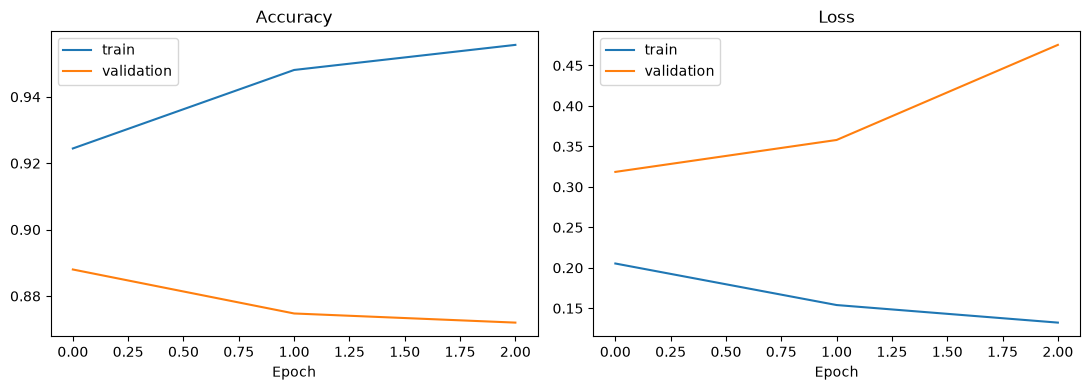

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(history.history['accuracy'], label='train')
ax[0].plot(history.history['val_accuracy'], label='validation')
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()

ax[1].plot(history.history['loss'], label='train')
ax[1].plot(history.history['val_loss'], label='validation')
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()

plt.tight_layout()
plt.show()

## 8. Evaluation

In [ ]:
y_proba = model.predict(X_test).ravel()          # probability of Positive
y_pred  = (y_proba >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
print("Model Accuracy:", round(acc * 100, 2), "%")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

## 9. Confidence Analysis

In [ ]:
# confidence = probability of the predicted class
confidence_scores = np.where(y_proba >= 0.5, y_proba, 1 - y_proba) * 100

plt.figure(figsize=(6, 4))
sns.histplot(confidence_scores, bins=30, kde=True)
plt.title("Distribution of Model Confidence Scores")
plt.xlabel("Confidence (%)")
plt.ylabel("Frequency")
plt.show()

order = confidence_scores.argsort()
print("Lowest confidence :", np.round(confidence_scores[order[:5]], 2))
print("Highest confidence:", np.round(confidence_scores[order[-5:]], 2))

## 10. Prediction Function

In [ ]:
def predict_sentiment(text, model=model, tokenizer=tokenizer):
    cleaned = clean_text(text)
    seq = pad_sequences(tokenizer.texts_to_sequences([cleaned]),
                        maxlen=MAX_LEN, padding='post', truncating='post')
    prob = float(model.predict(seq, verbose=0)[0][0])
    sentiment = "Positive" if prob >= 0.5 else "Negative"
    confidence = (prob if prob >= 0.5 else 1 - prob) * 100
    return sentiment, round(confidence, 2)

sample_reviews = [
    "This movie was absolutely fantastic, I loved every moment!",
    "The plot was boring and the acting was terrible.",
    "It was okay, not great but not bad either.",
    "I did not like this movie at all."
]

for review in sample_reviews:
    sentiment, confidence = predict_sentiment(review)
    print(f"Review: {review}")
    print(f"Prediction: {sentiment} ({confidence}% confident)")
    print("-" * 60)

## 11. Save Model and Tokenizer

In [ ]:
model.save("sentiment_lstm_model.keras")

with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("LSTM model and tokenizer saved successfully!")

## 12. Load and Predict

In [ ]:
loaded_model = load_model("sentiment_lstm_model.keras")
with open("tokenizer.pkl", "rb") as f:
    loaded_tokenizer = pickle.load(f)

print(predict_sentiment("The movie was visually stunning and emotionally powerful",
                        model=loaded_model, tokenizer=loaded_tokenizer))